In [2]:
# Verify our Python environment

import sys
import pandas as pd
import numpy as np
import sklearn

print("Python Version:", sys.version.split()[0])
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Scikit-learn Version:", sklearn.__version__)

print("\nEnvironment is ready!")

Python Version: 3.14.5
Pandas Version: 3.0.3
NumPy Version: 2.4.6
Scikit-learn Version: 1.9.0

Environment is ready!


In [3]:
# Import Pandas
import pandas as pd

# Load the Kaggle Iris dataset
df = pd.read_csv("Iris.csv")

# Display the first five rows
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


# Species Distribution

In this step, we examine the number of samples belonging to each Iris species.

Understanding the class distribution helps us identify whether the dataset is balanced or imbalanced.

In [5]:
# Count the number of samples in each species
print("Species Distribution:\n")

print(df["Species"].value_counts())

Species Distribution:

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


# Statistical Summary

We use descriptive statistics to understand the distribution and variability of the numerical features.

This helps us identify differences in flower measurements before performing exploratory data analysis.

In [6]:
# Generate descriptive statistics
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [ ]:
# Data Quality Check

We check the dataset for missing values and duplicate records to ensure data quality before performing exploratory data analysis.

In [7]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Number of Duplicate Rows:
0


### Feature Selection

The ID column is an identifier and does not represent any biological measurement of the flower.

Therefore, we exclude it from the analytical dataset and retain the four measurement features along with the target species.

In [8]:
# Remove the unnecessary ID column
iris_df = df.drop(columns=["Id"])

# Display the updated dataset
iris_df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the patterns, relationships, and distributions present in the Iris dataset.

In this section, we use different visualizations to explore the relationships between flower measurements and species.

In [9]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


# Pairplot Analysis

A pairplot is used to visualize pairwise relationships between numerical features in the dataset.

Different colors represent different Iris species. This helps identify patterns and determine which measurements are useful for distinguishing between species.

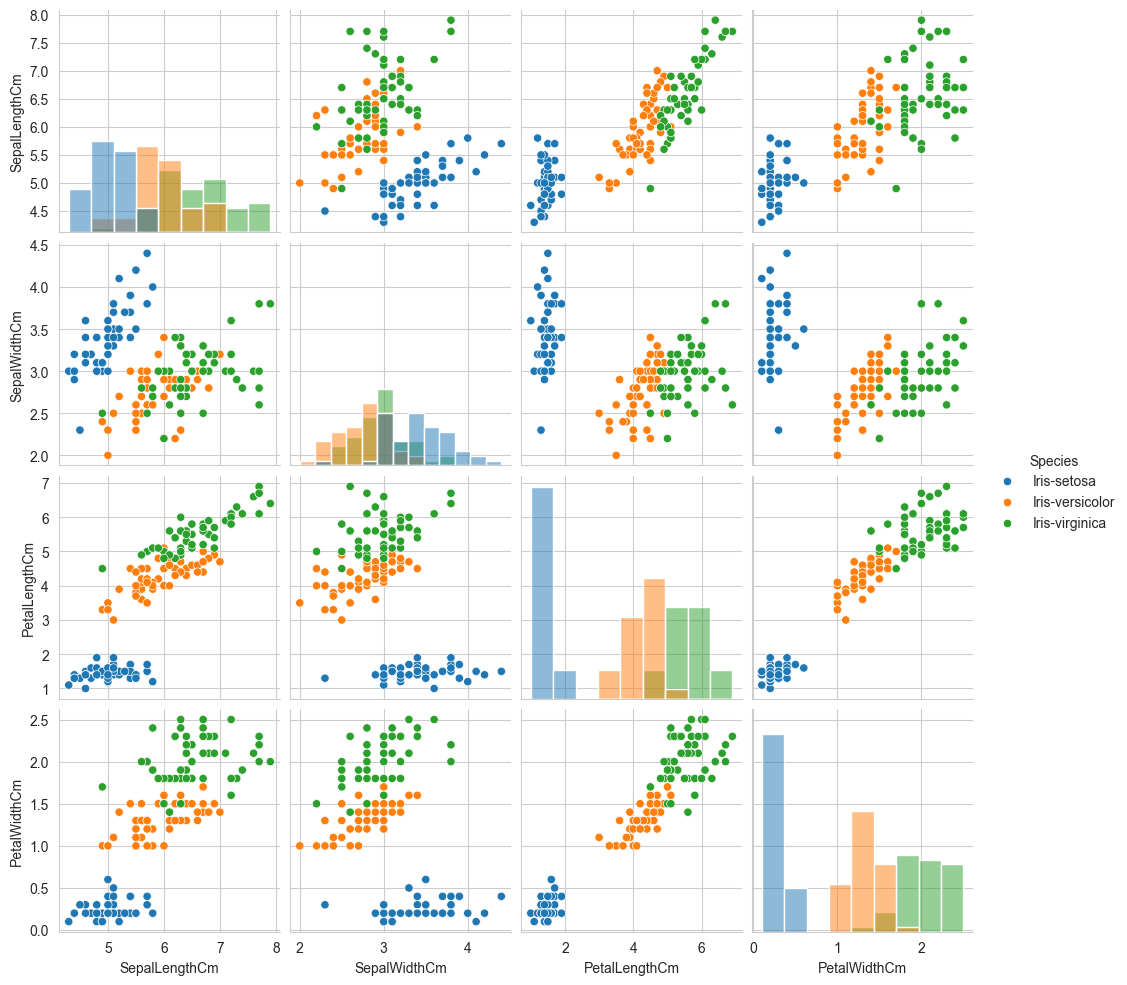

In [10]:
# Create a pairplot for all flower measurements
sns.pairplot(
    iris_df,
    hue="Species",
    diag_kind="hist"
)

# Display the visualization
plt.show()

# Correlation Heatmap

A correlation heatmap is used to identify the strength and direction of relationships between numerical features.

It helps us understand which flower measurements are strongly related to each other.

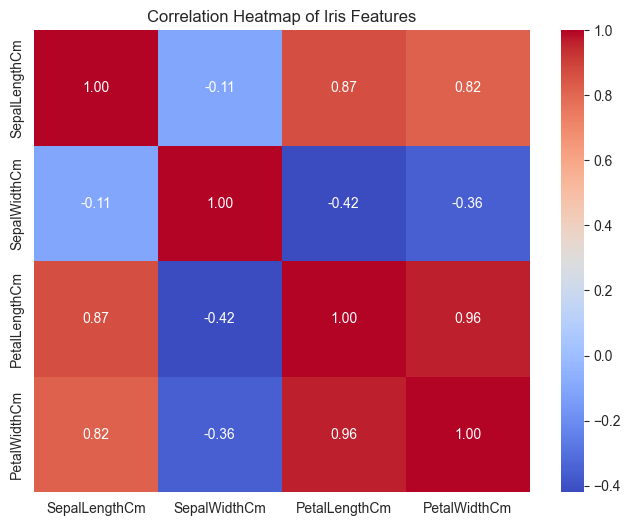

In [11]:
# Calculate correlation between numerical features
correlation = iris_df.drop(columns=["Species"]).corr()

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Features")
plt.show()

# Boxplot Analysis

Boxplots are used to compare the distribution of flower measurements across different Iris species.

They display the median, quartiles, spread of measurements, and potential outliers.

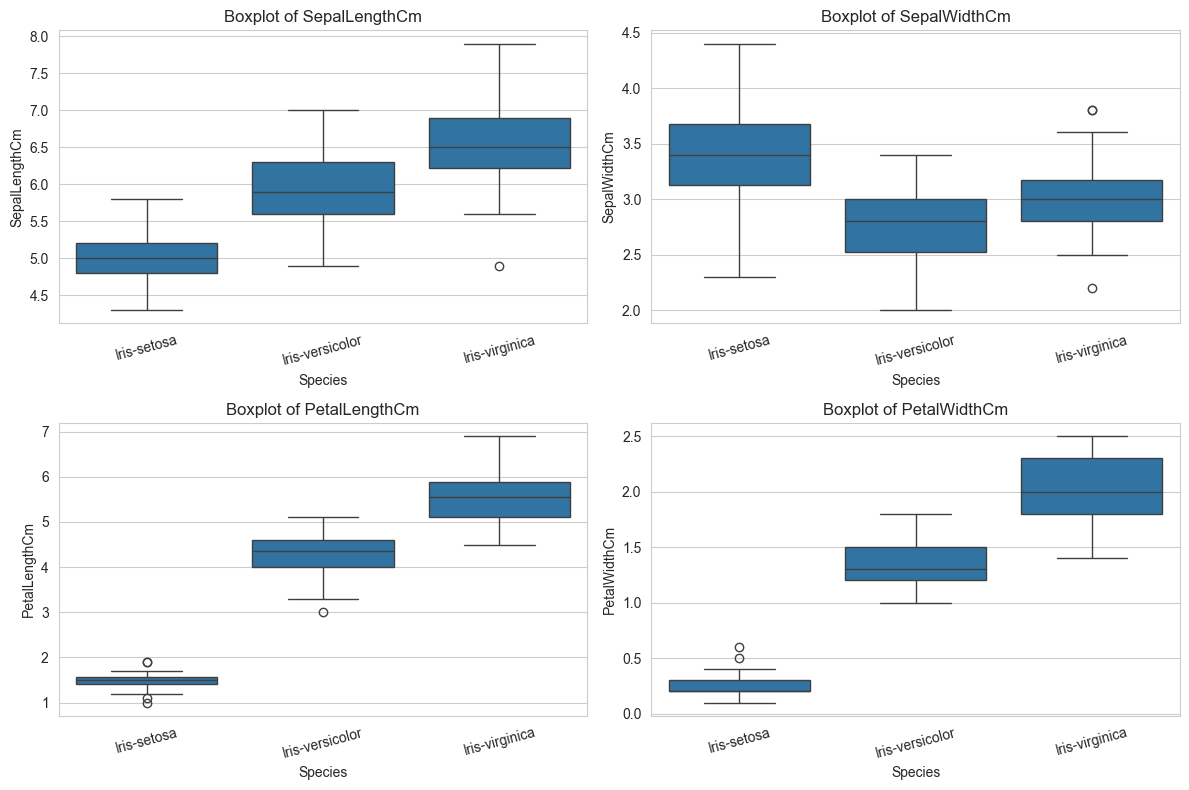

In [12]:
# Create boxplots for all numerical features
plt.figure(figsize=(12, 8))

for index, feature in enumerate(
    ["SepalLengthCm", "SepalWidthCm",
     "PetalLengthCm", "PetalWidthCm"], 1
):
    plt.subplot(2, 2, index)

    sns.boxplot(
        data=iris_df,
        x="Species",
        y=feature
    )

    plt.title(f"Boxplot of {feature}")
    plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# EDA Observations

Based on the visualizations, the following observations were made:

1. Iris-setosa forms a relatively distinct cluster compared to the other two species.
2. Iris-versicolor and Iris-virginica show some overlap in their measurement distributions.
3. Petal length and petal width provide useful information for distinguishing Iris species.
4. The correlation heatmap indicates a strong positive relationship between petal length and petal width.
5. Boxplots help compare the measurement distributions and identify potential outliers.

**Conclusion:**

The exploratory analysis indicates that flower measurements, particularly petal measurements, contain useful patterns for classifying the three Iris species.

In [ ]:
# Data Preprocessing

Data preprocessing involves preparing the dataset before training machine learning models.

In this section, we separate the input features from the target variable and prepare the data for model training and evaluation.

# Separating Features and Target

The four flower measurements are selected as input features (X), while the Species column is selected as the target variable (y).

The ID column is excluded because it does not contain meaningful flower measurements.

In [13]:
# Separate input features (X)
X = iris_df.drop(columns=["Species"])

# Separate target variable (y)
y = iris_df["Species"]

# Display the dimensions
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


# Label Encoding

Label encoding converts categorical species names into numerical values.

We use Scikit-learn's LabelEncoder to transform the target variable into numerical class labels for machine learning.

In [14]:
# Import LabelEncoder
from sklearn.preprocessing import LabelEncoder

# Create the encoder
label_encoder = LabelEncoder()

# Convert species names into numerical labels
y_encoded = label_encoder.fit_transform(y)

# Display the class mapping
for index, species in enumerate(label_encoder.classes_):
    print(f"{species} -> {index}")

print("\nEncoded Target:")
print(y_encoded[:10])

Iris-setosa -> 0
Iris-versicolor -> 1
Iris-virginica -> 2

Encoded Target:
[0 0 0 0 0 0 0 0 0 0]


# Train-Test Split

The dataset is divided into training and testing sets using Scikit-learn's train_test_split() function.

We allocate 80% of the data for training and 20% for testing.

The stratify parameter maintains the original class distribution in both sets, while random_state ensures reproducibility.

In [15]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)

Training Target: (120,)
Testing Target: (30,)


# Verification of Class Distribution

We verify the distribution of species in the training and testing sets to ensure that stratification has maintained balanced class representation.

In [16]:
# Check species distribution in training data
print("Training Set Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

# Check species distribution in testing data
print("\nTesting Set Distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training Set Distribution:
0    40
1    40
2    40
Name: count, dtype: int64

Testing Set Distribution:
0    10
1    10
2    10
Name: count, dtype: int64


#  Model Building

In this section, we train machine learning classification models using the preprocessed Iris dataset.

We begin with Logistic Regression as our baseline model to establish an initial performance benchmark.

# Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for classification tasks.

It learns the relationship between input features and target classes to predict the species of an Iris flower.

In [17]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(max_iter=200)

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


# Making Predictions

After training the Logistic Regression model, we use the testing features (X_test) to predict the corresponding Iris species.

These predictions will be compared with the actual species labels to evaluate the model's performance.

In [18]:
# Predict species using the testing data
y_pred = logistic_model.predict(X_test)

print("Actual Labels:    ", y_test)
print("Predicted Labels: ", y_pred)

Actual Labels:     [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Labels:  [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


# Evaluating Baseline Accuracy

Accuracy is the ratio of correctly predicted samples to the total number of testing samples.

We use the accuracy_score() function to measure the performance of our baseline Logistic Regression model.

In [19]:
from sklearn.metrics import accuracy_score

# Calculate model accuracy
baseline_accuracy = accuracy_score(y_test, y_pred)

print("Baseline Model Accuracy:", baseline_accuracy * 100, "%")

Baseline Model Accuracy: 96.66666666666667 %


# Model Comparison

In this section, we train and compare multiple machine learning classification algorithms to identify the best-performing model for the Iris dataset.

# Decision Tree Classifier

A Decision Tree is a supervised learning algorithm that makes predictions using a sequence of decision rules based on input features.

In [20]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)

# Train the model
decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


# Evaluating Decision Tree Accuracy

We use the trained Decision Tree model to predict the Iris species in the testing dataset.

The accuracy score helps us measure how well the model classifies unseen flower samples.

In [21]:
# Predict using Decision Tree
y_pred_tree = decision_tree.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


# Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve classification performance.

Each tree makes a prediction, and the final class is selected through majority voting.

In [22]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


# Evaluating Random Forest Accuracy

The trained Random Forest model is used to predict the species of flowers in the testing dataset.

Its accuracy is calculated to compare its performance with Logistic Regression and Decision Tree.

In [23]:
# Predict using Random Forest
y_pred_forest = random_forest.predict(X_test)

# Calculate accuracy
forest_accuracy = accuracy_score(y_test, y_pred_forest)

print("Random Forest Accuracy:", forest_accuracy * 100, "%")

Random Forest Accuracy: 90.0 %


# Support Vector Machine (SVM)

Support Vector Machine is a supervised machine learning algorithm used for classification.

It identifies an optimal decision boundary that separates different classes based on their input features.

In [24]:
from sklearn.svm import SVC

# Create the SVM model
svm_model = SVC()

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


# Evaluating SVM Accuracy

The trained SVM model is used to predict the Iris species in the testing dataset.

Its accuracy is calculated and compared with the previously trained classification models.

In [25]:
# Predict using SVM
y_pred_svm = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 96.66666666666667 %


# K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised machine learning algorithm that classifies a sample based on the majority class among its nearest neighbors.

Feature scaling is applied before KNN because the algorithm uses distances to identify neighboring samples.

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create the KNN model with feature scaling
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


# Evaluating KNN Accuracy

The trained KNN model predicts the species of flowers in the testing dataset.

Its accuracy is calculated to compare its performance with the other classification algorithms.

In [27]:
# Predict using KNN
y_pred_knn = knn_model.predict(X_test)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 93.33333333333333 %


# Comparing All Classification Models

The accuracy scores of all five trained classification models are organized into a comparison table.

This helps identify which algorithm performs best on the testing dataset.

In [28]:
# Create a model comparison table
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN"
    ],
    "Accuracy (%)": [
        baseline_accuracy * 100,
        tree_accuracy * 100,
        forest_accuracy * 100,
        svm_accuracy * 100,
        knn_accuracy * 100
    ]
})

# Sort models by accuracy
model_results = model_results.sort_values(
    by="Accuracy (%)", ascending=False
).reset_index(drop=True)

model_results

,Model,Accuracy (%)
0,Logistic Regression,96.666667
1,SVM,96.666667
2,Decision Tree,93.333333
3,KNN,93.333333
4,Random Forest,90.000000


# Detailed Model Evaluation

In this section, we evaluate the classification models using precision, recall, F1-score and confusion matrices.

These metrics provide a more detailed understanding of model performance beyond accuracy.

# Classification Report

A classification report displays precision, recall, F1-score and support for each class.

In [29]:
from sklearn.metrics import classification_report

# Generate classification report for Logistic Regression
print("Logistic Regression Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

Logistic Regression Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



# Confusion Matrix

A confusion matrix is used to evaluate the performance of a classification model.

It compares actual class labels with predicted class labels and displays the number of correct and incorrect predictions.

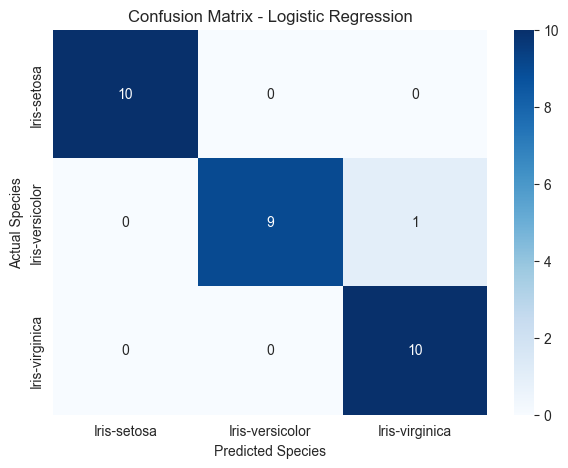

In [30]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# Cross-Validation

Cross-validation is a model evaluation technique that divides the training dataset into multiple folds.

In 5-fold cross-validation, the model is trained and evaluated five times using different portions of the training data.

The average accuracy provides a more reliable estimate of model performance.

In [31]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross-Validation Scores:", cv_scores)
print("Mean Cross-Validation Accuracy:", cv_scores.mean() * 100, "%")

Cross-Validation Scores: [0.95833333 0.95833333 0.95833333 0.95833333 1.        ]
Mean Cross-Validation Accuracy: 96.66666666666669 %


# Classification Reports for Other Models

Classification reports are generated for Decision Tree, Random Forest, SVM and KNN.

This allows us to compare their precision, recall and F1-score for each Iris species.

In [32]:
# Store model predictions
predictions = {
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn
}

# Generate classification reports
for model_name, predictions_value in predictions.items():
    print(f"\n{model_name} Classification Report:\n")
    print(classification_report(
        y_test,
        predictions_value,
        target_names=label_encoder.classes_
    ))


Decision Tree Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30


Random Forest Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30


SVM Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00     

In [33]:
print("SVM Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=label_encoder.classes_
))

print("\nKNN Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=label_encoder.classes_
))

SVM Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30


KNN Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



# Hyperparameter Tuning

Hyperparameter tuning is used to find the best model settings to improve performance.

In this project, GridSearchCV is used to test different Logistic Regression hyperparameter combinations using cross-validation.

# Importing GridSearchCV

GridSearchCV performs an exhaustive search over the specified parameter combinations and selects the best-performing configuration.

In [34]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


# Defining the Parameter Grid

A parameter grid contains the hyperparameter values that GridSearchCV will evaluate.

We test different regularization strengths (C) and optimization solvers to identify a suitable Logistic Regression configuration.

In [35]:
# Define hyperparameter values
param_grid = {
    "C": [0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear"]
}

print("Parameter Grid:")
print(param_grid)

Parameter Grid:
{'C': [0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}


# Performing Grid Search

GridSearchCV evaluates all specified hyperparameter combinations using 5-fold cross-validation.

The configuration with the highest mean validation accuracy is selected as the best parameter combination.

In [37]:
# Update parameter grid
param_grid = {
    "C": [0.1, 1, 10, 100],
    "solver": ["lbfgs"]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    LogisticRegression(max_iter=200),
    param_grid,
    cv=5,
    scoring="accuracy"
)

# Perform grid search
grid_search.fit(X_train, y_train)

print("Grid Search completed successfully!")

Grid Search completed successfully!


# Identifying the Best Parameters

After completing GridSearchCV, we retrieve the best hyperparameter combination and its corresponding mean cross-validation accuracy.

These values help identify the most suitable Logistic Regression configuration.

In [38]:
print("Best Parameters:", grid_search.best_params_)

print(
    "Best Cross-Validation Accuracy:",
    grid_search.best_score_ * 100,
    "%"
)

Best Parameters: {'C': 1, 'solver': 'lbfgs'}
Best Cross-Validation Accuracy: 96.66666666666669 %


# Training the Tuned Model

We create a new Logistic Regression model using the best parameters identified by GridSearchCV.

The tuned model is trained using the training dataset to prepare it for final evaluation.

In [39]:
# Create model using the best parameters
best_model = grid_search.best_estimator_

# Train the tuned model
best_model.fit(X_train, y_train)

print("Tuned Logistic Regression model trained successfully!")

Tuned Logistic Regression model trained successfully!


# Evaluating the Tuned Model

The tuned model is evaluated using the testing dataset.

Its accuracy is compared with the baseline Logistic Regression model to observe whether hyperparameter tuning improved performance.

In [40]:
# Predict using the tuned model
y_pred_tuned = best_model.predict(X_test)

# Calculate tuned model accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Baseline Accuracy:", baseline_accuracy * 100, "%")
print("Tuned Model Accuracy:", tuned_accuracy * 100, "%")

Baseline Accuracy: 96.66666666666667 %
Tuned Model Accuracy: 96.66666666666667 %


# Making Predictions

In this section, we create a reusable prediction function using the tuned Logistic Regression model.

The function accepts four flower measurements and predicts the corresponding Iris species.

# Creating a Prediction Function

The function accepts sepal length, sepal width, petal length, and petal width as inputs.

It uses the trained model to predict the flower species and converts the encoded prediction back into its original species name.

In [42]:
def predict_iris(sepal_length, sepal_width, petal_length, petal_width):
    input_data = pd.DataFrame(
        [[sepal_length, sepal_width, petal_length, petal_width]],
        columns=X.columns
    )

    prediction = best_model.predict(input_data)

    predicted_species = label_encoder.inverse_transform(prediction)

    return predicted_species[0]

In [43]:
result = predict_iris(5.1, 3.5, 1.4, 0.2)

print("Predicted Iris Species:", result)

Predicted Iris Species: Iris-setosa


In [44]:
result = predict_iris(6.3, 3.3, 6.0, 2.5)

print("Predicted Iris Species:", result)

Predicted Iris Species: Iris-virginica


# Conclusion

The Iris Flower Classification project was successfully implemented using supervised machine learning techniques.

The dataset contained 150 flower samples belonging to three species: Iris-setosa, Iris-versicolor, and Iris-virginica.

Exploratory Data Analysis helped identify relationships between flower measurements and differences among species.

Five machine learning algorithms were trained and compared:

- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine (SVM)
- K-Nearest Neighbors (KNN)

Logistic Regression and Support Vector Machine achieved the highest test accuracy of 96.67%.

GridSearchCV was applied to tune the Logistic Regression model. The best parameters were C = 1 and solver = lbfgs. The tuned model also achieved 96.67% test accuracy.

Finally, a reusable prediction function was developed to predict Iris flower species from four input measurements.

This project provided practical experience in data preprocessing, exploratory data analysis, model training, evaluation, hyperparameter tuning, and prediction using Python and Scikit-learn.